In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_mutual_info_score, silhouette_score

In [ ]:
#HIZ KAZANMAK ADINA VERİNİN HEPSİNİ ALMADIK
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X = mnist.data[:10000]
y = mnist.target[:10000].astype(int)

In [3]:
#VERİYİ İNDİRGEME YAPIYORUZ Kİ GMM ALGORİTMASINDAN OPTİMUM VERİM ALABİLELİM
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X_scaled)

In [4]:
n_components_range = [5, 10, 15, 20]
ami_scores = []
bic_scores = []

AMI : KÜMELEME SONUÇLARINI GERÇEK ETİKETLER İLE KIYASLAYAN BİR BAŞARI ÖLÇÜTÜ. AYARLANMIŞ DEMEK RASTLANTISAL İLE OLUŞABİLECEK KÜMELERİ İFADE EDER. AMI 1 E NE KADAR YAKINSA O KADAR İYİ DENEBİLİR.
BIC: MODELİN KARMAŞIKLIĞI İLE VERİYE UYUMU ARASINDAKİ DENGEYİ ÖLÇER Bir modeli çok fazla bileşenle (çok yüksek $K$ değeri) eğitirsen veriye çok iyi uyar ama bu "aşırı öğrenme" (overfitting) demektir. BIC, gereksiz her yeni bileşen için modele bir ceza puanı keser.
EN İYİ BIC İÇİN ELBOW METODU ARARIZ

In [ ]:
#BURADA FARKLI K DEĞERLERİ İÇİN AMI VE BICLERE BAKMAK ADINA BİR DÖNGÜ TANIMLIYORUZ
for n in n_components_range:
    print(f"GMM eğitiliyor: n_components={n}")
    gmm = GaussianMixture(n_components=n, random_state=42, n_init=2)
    labels = gmm.fit_predict(X_pca)
    
    # AMI Skoru (Adjusted Mutual Information)
    ami = adjusted_mutual_info_score(y, labels)
    ami_scores.append(ami)
    bic_scores.append(gmm.bic(X_pca))

GMM eğitiliyor: n_components=5
GMM eğitiliyor: n_components=10
GMM eğitiliyor: n_components=15
GMM eğitiliyor: n_components=20


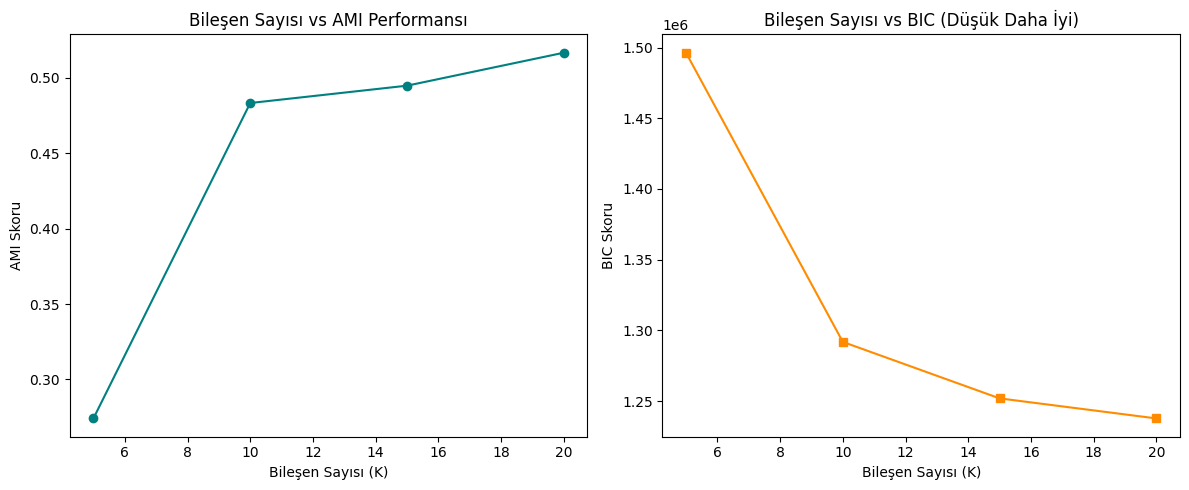

In [12]:
plt.figure(figsize=(12, 5))

# AMI Grafiği
plt.subplot(1, 2, 1)
plt.plot(n_components_range, ami_scores, marker='o', color='teal')
plt.title("Bileşen Sayısı vs AMI Performansı")
plt.xlabel("Bileşen Sayısı (K)")
plt.ylabel("AMI Skoru")

# BIC Grafiği (Optimum noktayı görmek için)
plt.subplot(1, 2, 2)
plt.plot(n_components_range, bic_scores, marker='s', color='darkorange')
plt.title("Bileşen Sayısı vs BIC (Düşük Daha İyi)")
plt.xlabel("Bileşen Sayısı (K)")
plt.ylabel("BIC Skoru")

plt.tight_layout()
plt.show()

AMI VE BICE BAKTIĞIMIZDA MODELİN OVERFİTTİNGİ ENGELLEMEK ADINA VE YENİ VERİLERDE DAHA İYİ ÇALIŞACAĞINI K= 10'DA DİYEBİLİRİZ. K ARTTIKÇA DAHA İYİ SONUÇ GÖZÜKMEKTEDİR ANCAK MODELİMİZ EZBERLEMİŞ OLABİLİR.

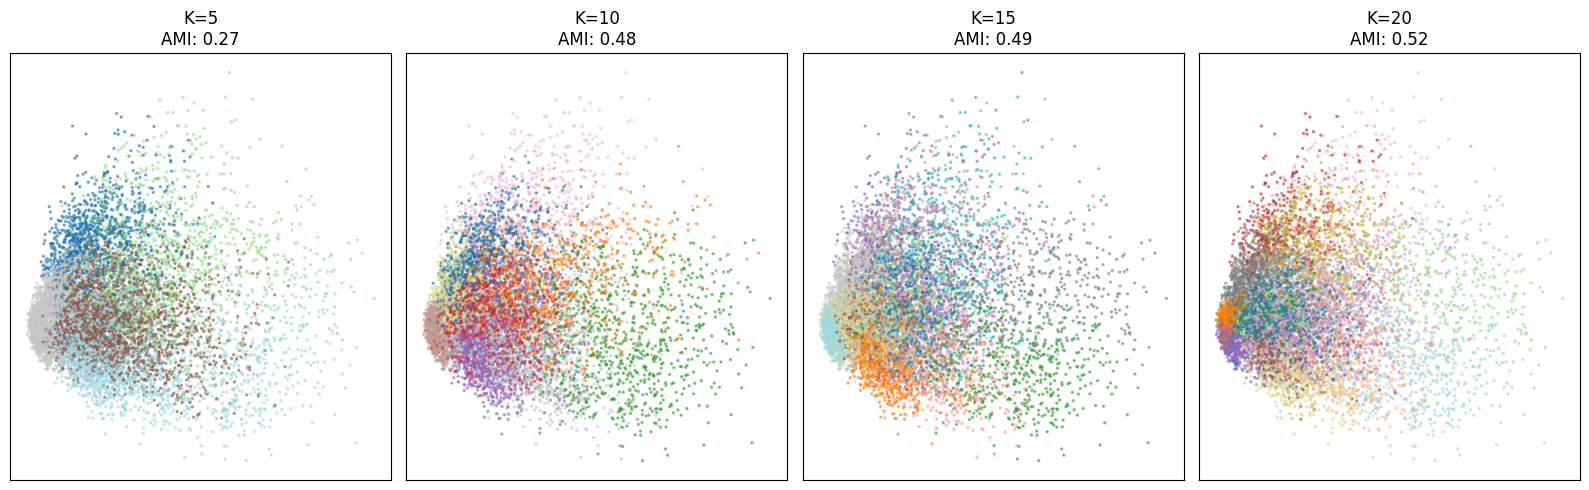

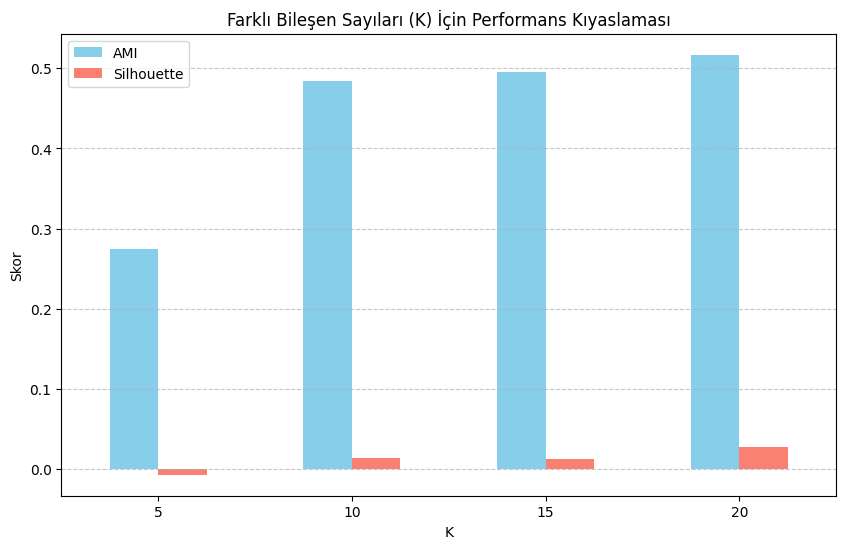

In [13]:
n_components_range = [5, 10, 15, 20]
results = []
plt.figure(figsize=(16, 5))

for i, n in enumerate(n_components_range):
    # GMM Modelini eğit
    gmm = GaussianMixture(n_components=n, random_state=42, n_init=2)
    labels = gmm.fit_predict(X_pca)
    
    # Metrikleri hesapla
    ami = adjusted_mutual_info_score(y, labels)
    sil = silhouette_score(X_pca, labels)
    results.append({"K": n, "AMI": ami, "Silhouette": sil})
    
    # Kümeleme sonuçlarını görselleştir (İlk 2 PCA bileşeni üzerinden)
    plt.subplot(1, len(n_components_range), i+1)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, s=2, cmap='tab20', alpha=0.5)
    plt.title(f"K={n}\nAMI: {ami:.2f}")
    plt.xticks([]); plt.yticks([])

plt.tight_layout()
plt.show()

# 2. Skorları Bar Grafiği ile Karşılaştır
df_res = pd.DataFrame(results)
df_res.set_index('K')[['AMI', 'Silhouette']].plot(kind='bar', figsize=(10, 6), color=['skyblue', 'salmon'])
plt.title("Farklı Bileşen Sayıları (K) İçin Performans Kıyaslaması")
plt.ylabel("Skor")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()